# Genshin Impact Wish History Analysis (2021–2026)
**Data Analyst portfolio project**

**Questions:**
1. How many pulls does it take on average to get a 5-star?
2. Is *soft pity* (a sharp rise in odds around pull 74) visible in real data?
3. How often is the 50/50 won or lost?
4. How has pulling behaviour changed over time?
5. What is the rupiah-equivalent value of one 5-star?

**Data source:** personal wish history exported from paimon.moe (secondary data, no survey respondents).

**Context for non-players:** Genshin Impact uses a *gacha* system. One "pull" is one random draw (160 Primogems).
The official base rate for a 5-star on the character banner is 0.6%, with a guaranteed 5-star by pull 90 (*hard pity*).
When a 5-star drops on the character banner there is roughly a 50% chance it is the featured character; if you "lose the 50/50",
your next 5-star is guaranteed to be the featured character.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Chart style: thin marks, subtle grid
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8c8b85", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

## 2. Upload the data
Run the cell below and choose `paimonmoe_wish_history.xlsx` from your computer.
(Outside Colab, just set `FILE` to the file's location.)

In [2]:
FILE = "paimonmoe_wish_history.xlsx"
try:
    from google.colab import files
    uploaded = files.upload()
    FILE = list(uploaded.keys())[0]
except ImportError:
    pass  # not running in Colab: use the FILE path above
print("Using file:", FILE)

Using file: paimonmoe_wish_history.xlsx


## 3. Load & clean the data

In [3]:
SHEETS = {"Character Event": "Character", "Weapon Event": "Weapon", "Standard": "Standard"}

frames = []
for sheet, label in SHEETS.items():
    d = pd.read_excel(FILE, sheet_name=sheet)
    d["Banner Type"] = label
    d["Order"] = range(1, len(d) + 1)   # original pull order in the sheet (already chronological)
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df = df.rename(columns={"⭐": "Rarity"})
df["Time"] = pd.to_datetime(df["Time"])
df = df.sort_values(["Banner Type", "Order"]).reset_index(drop=True)

# Data quality check
print("Total pulls:", len(df))
print("Missing values per column:")
print(df[["Type", "Name", "Time", "Rarity", "Pity"]].isna().sum())
df.head()

Total pulls: 7115
Missing values per column:
Type      0
Name      0
Time      0
Rarity    0
Pity      0
dtype: int64


,Type,Name,Time,Rarity,Pity,#Roll,Group,Banner,Part,Banner Type,Order
0,Weapon,Slingshot,2021-11-02 18:22:06,3,1,1,1,Moment of Bloom,NaN,Character,1
1,Weapon,Sharpshooter's Oath,2021-11-02 18:22:14,3,1,2,2,Moment of Bloom,NaN,Character,2
2,Weapon,Ferrous Shadow,2021-11-02 18:22:21,3,1,3,3,Moment of Bloom,NaN,Character,3
3,Weapon,Bloodtainted Greatsword,2021-11-02 18:22:27,3,1,4,4,Moment of Bloom,NaN,Character,4
4,Weapon,Favonius Codex,2021-11-02 18:22:33,4,5,5,5,Moment of Bloom,NaN,Character,5


**Recalculate pity.** paimon.moe's `Pity` column is counted per rarity, so for the probability analysis we need a
"pulls since the last 5-star" counter on *every* row.

In [4]:
def pity_since_5star(g):
    pity, out = 0, []
    for r in g["Rarity"]:
        pity += 1
        out.append(pity)
        if r == 5:
            pity = 0
    return pd.Series(out, index=g.index)

df["Pity5"] = df.groupby("Banner Type", group_keys=False).apply(pity_since_5star)
five_stars = df[df["Rarity"] == 5].copy()

# Validation: our pity count must match paimon.moe's Pity column for every 5-star
print("Pity matches paimon.moe:", (five_stars["Pity5"] == five_stars["Pity"]).all())
five_stars[["Banner Type", "Name", "Time", "Pity5"]].tail(10)

Pity matches paimon.moe: True


,Banner Type,Name,Time,Pity5
6564,Weapon,A Thousand Blazing Suns,2025-01-01 11:07:28,71
6631,Weapon,Symphonist of Scents,2025-05-07 11:32:06,67
6698,Weapon,Azurelight,2025-06-18 11:18:18,67
6764,Weapon,Bloodsoaked Ruins,2025-10-02 12:55:58,66
6814,Weapon,The Daybreak Chronicles,2025-12-03 19:37:43,50
6878,Weapon,Athame Artis,2025-12-03 20:02:56,64
6948,Weapon,Starcaller's Watch,2026-07-12 23:47:53,70
7014,Weapon,A Teaspoon of Transcendence,2026-07-12 23:49:21,66
7074,Weapon,Hymn of the Maelstrom,2026-10-03 23:49:16,60
7105,Weapon,Beyond the Chrysalis,2026-10-07 10:06:36,31


## 4. Overview

In [5]:
summary = df.groupby("Banner Type").agg(
    Total_Pulls=("Name", "size"),
    First_Pull=("Time", "min"),
    Last_Pull=("Time", "max"),
    Five_Stars=("Rarity", lambda r: (r == 5).sum()),
    Four_Stars=("Rarity", lambda r: (r == 4).sum()),
)
summary["Avg_Pulls_per_5Star"] = (summary["Total_Pulls"] / summary["Five_Stars"]).round(1)
summary["First_Pull"] = summary["First_Pull"].dt.date
summary["Last_Pull"] = summary["Last_Pull"].dt.date
summary

,Total_Pulls,First_Pull,Last_Pull,Five_Stars,Four_Stars,Avg_Pulls_per_5Star
Banner Type,,,,,,
Character,4593,2021-11-02,2026-11-04,76,600,60.4
Standard,862,2021-10-13,2026-09-23,15,112,57.5
Weapon,1660,2021-11-07,2026-10-07,30,250,55.3


## 5. 5-star pity distribution: is soft pity visible?

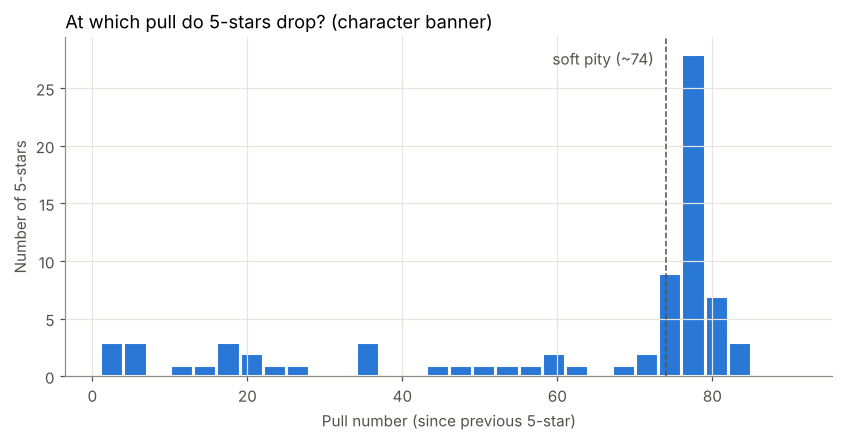

Mean pity   : 60.0
Median pity : 76
Dropped at pull 74–90: 62% of all 5-stars


In [6]:
char5 = five_stars[five_stars["Banner Type"] == "Character"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(char5["Pity5"], bins=range(1, 92, 3), color=BLUE, edgecolor="white", linewidth=2)
ax.axvline(74, color="#52514e", linestyle="--", linewidth=1)
ax.text(73, ax.get_ylim()[1] * 0.92, "soft pity (~74) ", color="#52514e", ha="right")
ax.set_title("At which pull do 5-stars drop? (character banner)", loc="left", fontsize=12)
ax.set_xlabel("Pull number (since previous 5-star)")
ax.set_ylabel("Number of 5-stars")
plt.show()

print(f"Mean pity   : {char5['Pity5'].mean():.1f}")
print(f"Median pity : {char5['Pity5'].median():.0f}")
print(f"Dropped at pull 74–90: {(char5['Pity5'] >= 74).mean():.0%} of all 5-stars")

### 5-star probability at each pull (*hazard rate*)
The question: *given that you have reached pull n without a 5-star, what is the chance that pull n gives one?*
This shows soft pity more precisely than a plain histogram.

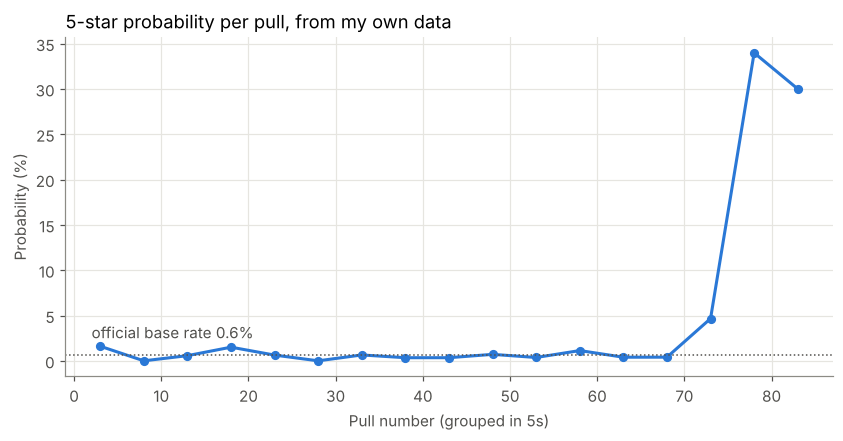

Average probability, pulls 1–73 : 0.66%
Average probability, pulls 74+  : 23.04%


In [7]:
char = df[df["Banner Type"] == "Character"]
reached = char.groupby("Pity5").size()                       # how many times pull n happened
hit = char[char["Rarity"] == 5].groupby("Pity5").size()      # how many times pull n was a 5-star

# group into 5-pull buckets to reduce noise
hz = pd.DataFrame({"reached": reached, "hit": hit.reindex(reached.index, fill_value=0)})
bucket = (hz.index - 1) // 5 * 5 + 1
hz_bucket = hz.groupby(bucket).sum()
hz_bucket["Probability"] = hz_bucket["hit"] / hz_bucket["reached"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hz_bucket.index + 2, hz_bucket["Probability"] * 100, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.axhline(0.6, color="#52514e", linestyle=":", linewidth=1)
ax.text(2, 2.5, "official base rate 0.6%", color="#52514e")
ax.set_title("5-star probability per pull, from my own data", loc="left", fontsize=12)
ax.set_xlabel("Pull number (grouped in 5s)")
ax.set_ylabel("Probability (%)")
plt.show()

rate_before = hz.loc[:73, "hit"].sum() / hz.loc[:73, "reached"].sum()
rate_after = hz.loc[74:, "hit"].sum() / hz.loc[74:, "reached"].sum()
print(f"Average probability, pulls 1–73 : {rate_before:.2%}")
print(f"Average probability, pulls 74+  : {rate_after:.2%}")

## 6. Winning / losing the 50/50
A 5-star counts as a **lost 50/50** when it is a *standard* character (not the featured one).
The standard pool has grown over time, so each character's **date of joining** is used:
- Tighnari joined the standard pool in version 3.1 (28 Sep 2022)
- Dehya in version 3.6 (12 Apr 2023)
- Yumemizuki Mizuki in version 5.5 (26 Mar 2025)

If new standard characters are added later, add them to the dictionary below.

Status of each 5-star:
- **Lost** = got a standard character
- **Guaranteed** = the previous 5-star was lost, so this one is guaranteed featured (not counted as a 50/50)
- **Won** = got the featured character without a guarantee

In [8]:
STANDARD = {
    "Diluc": "2020-01-01", "Jean": "2020-01-01", "Qiqi": "2020-01-01",
    "Mona": "2020-01-01", "Keqing": "2020-01-01",
    "Tighnari": "2022-09-28", "Dehya": "2023-04-12", "Yumemizuki Mizuki": "2025-03-26",
}
STANDARD = {k: pd.Timestamp(v) for k, v in STANDARD.items()}

def is_standard(row):
    return row["Name"] in STANDARD and row["Time"] >= STANDARD[row["Name"]]

c5 = char5.sort_values("Order").copy()
status, lost_previous = [], False
for _, row in c5.iterrows():
    if lost_previous:
        status.append("Guaranteed"); lost_previous = False
    elif is_standard(row):
        status.append("Lost"); lost_previous = True
    else:
        status.append("Won")
c5["Status"] = status

result = c5["Status"].value_counts()
won, lost = result.get("Won", 0), result.get("Lost", 0)
print(result.to_string())
print(f"\n50/50 win rate: {won}/{won+lost} = {won/(won+lost):.0%}")

Status
Won           28
Lost          24
Guaranteed    24

50/50 win rate: 28/52 = 54%


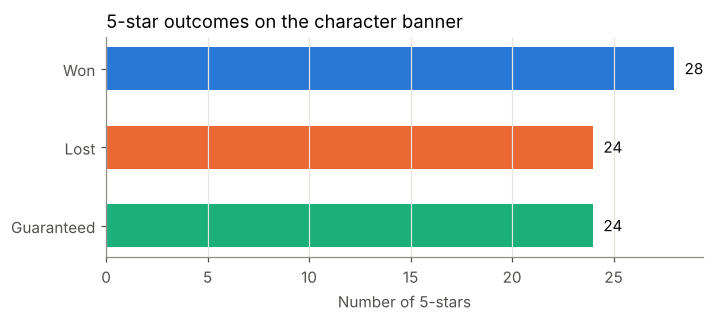

Name
Mona                 5
Keqing               5
Tighnari             3
Diluc                3
Jean                 3
Dehya                2
Qiqi                 2
Yumemizuki Mizuki    1
Name: count, dtype: int64

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
order = ["Won", "Lost", "Guaranteed"]
values = [result.get(s, 0) for s in order]
ax.barh(order, values, color=[BLUE, ORANGE, AQUA], height=0.55)
for y, v in enumerate(values):
    ax.text(v + 0.5, y, str(v), va="center", color="#0b0b0b")
ax.invert_yaxis()
ax.set_title("5-star outcomes on the character banner", loc="left", fontsize=12)
ax.set_xlabel("Number of 5-stars")
ax.grid(axis="y", visible=False)
plt.show()

# Which standard characters caused the lost 50/50s
c5[c5["Status"] == "Lost"]["Name"].value_counts()

## 7. Pulling behaviour over time

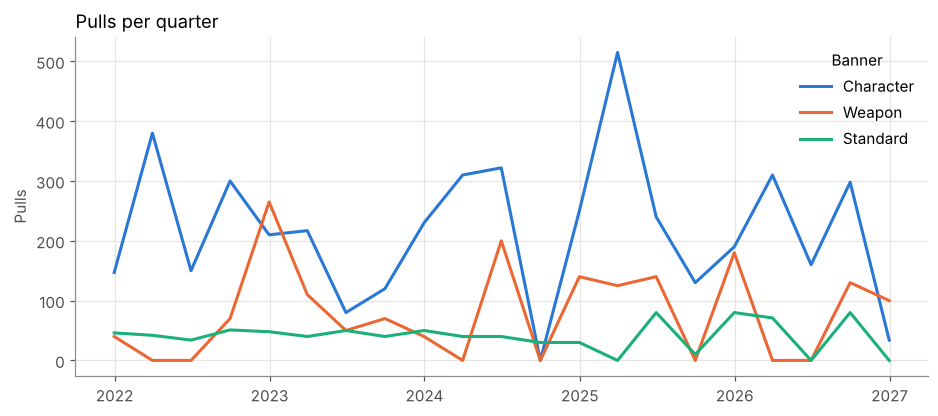

Banner Type,Character,Standard,Weapon,Total
Year,,,,
2021,147,46,40,233
2022,1040,175,335,1550
2023,647,180,270,1097
2024,882,140,340,1362
2025,1075,170,445,1690
2026,802,151,230,1183


In [10]:
per_quarter = (df.set_index("Time").groupby("Banner Type").resample("QE").size()
                 .unstack(0).fillna(0))

fig, ax = plt.subplots(figsize=(10, 4))
colors = {"Character": BLUE, "Weapon": ORANGE, "Standard": AQUA}
for col in ["Character", "Weapon", "Standard"]:
    if col in per_quarter:
        ax.plot(per_quarter.index, per_quarter[col], label=col, color=colors[col], linewidth=2)
ax.set_title("Pulls per quarter", loc="left", fontsize=12)
ax.set_ylabel("Pulls")
ax.legend(frameon=False, title="Banner")
plt.show()

per_year = df.groupby([df["Time"].dt.year.rename("Year"), "Banner Type"]).size().unstack(fill_value=0)
per_year["Total"] = per_year.sum(axis=1)
per_year

## 8. Rupiah-equivalent value
1 pull = 160 Primogems = 160 Genesis Crystals. The pack price is taken from Indonesian top-up reseller prices
(6480+1600 Crystals ≈ Rp1,629,000, August 2026). **Update these numbers if prices change.**

Important: many pulls usually come from free Primogems, so this is an **equivalent value**, not actual money spent.

In [11]:
PACK_PRICE_IDR = 1_629_000
CRYSTALS_PER_PACK = 6480 + 1600
IDR_PER_PULL = PACK_PRICE_IDR / CRYSTALS_PER_PACK * 160

value = summary[["Total_Pulls", "Five_Stars"]].copy()
value["Total_Value_IDR"] = value["Total_Pulls"] * IDR_PER_PULL
value["IDR_per_5Star"] = value["Total_Value_IDR"] / value["Five_Stars"]
print(f"Equivalent value of 1 pull: Rp{IDR_PER_PULL:,.0f}")
value.style.format({"Total_Value_IDR": "Rp{:,.0f}", "IDR_per_5Star": "Rp{:,.0f}"})

Equivalent value of 1 pull: Rp32,257


,Total_Pulls,Five_Stars,Total_Value_IDR,IDR_per_5Star
Banner Type,,,,
Character,4593,76,"Rp148,158,356","Rp1,949,452"
Standard,862,15,"Rp27,805,901","Rp1,853,727"
Weapon,1660,30,"Rp53,547,327","Rp1,784,911"


## 9. Key insights

In [12]:
print(f"• {len(df):,} pulls from {df['Time'].min():%b %Y} to {df['Time'].max():%b %Y}.")
print(f"• Character banner: {char5['Pity5'].mean():.1f} pulls per 5-star on average; "
      f"{(char5['Pity5'] >= 74).mean():.0%} of 5-stars dropped at pull 74 or later → soft pity confirmed.")
print(f"• 5-star probability rises from {rate_before:.1%} (pulls 1–73) to {rate_after:.1%} (pulls 74+).")
print(f"• 50/50 win rate: {won/(won+lost):.0%} ({won} won, {lost} lost).")
print(f"• Equivalent value of one character-banner 5-star ≈ Rp{value.loc['Character','IDR_per_5Star']:,.0f}.")

• 7,115 pulls from Oct 2021 to Nov 2026.
• Character banner: 60.0 pulls per 5-star on average; 62% of 5-stars dropped at pull 74 or later → soft pity confirmed.
• 5-star probability rises from 0.7% (pulls 1–73) to 23.0% (pulls 74+).
• 50/50 win rate: 54% (28 won, 24 lost).
• Equivalent value of one character-banner 5-star ≈ Rp1,949,452.


**Limitations:**
- Data comes from a single account, so results may differ from the overall player population.
- 50/50 status is inferred from the standard character list. The *Capturing Radiance* mechanic (since version 5.0)
  may affect win odds and is not directly visible in the data.
- Rupiah values are estimates based on top-up prices, not actual spending.

**Next steps:** compare with a larger community dataset, analyse the weapon banner (Epitomized Path), or run a statistical
test on whether the 50/50 win rate differs significantly from 50% (*binomial test*).